In [2]:
%load_ext autoreload
%autoreload 2   

# Task 4.6 - Scenario Analysis

Basics shared across the scenarios:

$N(t) = N_C(t) + N_T(t) + N_B(t)$ - The total number of vessel arrivals in period $[0, t]$ is equal to the sum of respectively the number of Container, Tanker and Bulk vessel arrivals on the same period.

$S(t) = S_C(t) + S_T(t) + S_B(t)$ - The total amount of cargo handled by all the vesels in period $[0,t]$ is equal to the sum of the total amount of cargo (in tons) for all Container, Tanker and Bulk vessels in the same period.

## Chosen scenarios:

Each alternative scenario changes one aspect of the basic scenario while keeping everything else the same, so that the differences in the results can be attributed to that single change. The seasonal scenario is also the model chosen in 4.4, the larger-vessels and weather scenarios are built on the basic scenario to isolate their own effect.

- Basic: All vessel arrival processes are homogenous Poisson processes, the amount of cargo per vessel is assumed to have a lognormal distribution. Each vessel type has its own set of parameters.
- Seasonality: The arrival of vessels has a seasonality effect, with the rate of arrival $\lambda_m$ differing for each month $m \in [1, 12]$
- Larger vessels: The same trade volume is carried by fewer, larger ships. Each vessel carries 20% more cargo, and the arrival rates are reduced so that the expected total cargo stays unchanged.
- Weather Disruptions: On days with bad weather the port is closed or slowed down, and the cargo that cannot be handled is delayed to the next day.


### Basic Scenario

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from toolkit import load_data, moments, fit_lognormal, simCPP, simDailyCPP, applyWeather
np.random.seed(42)

In [4]:
df = load_data()

d = df['Arrival_Date']
n_days = d.dt.normalize().nunique()

arr_daily = len(df) / n_days
arr_daily_per_type = df.groupby("Vessel_Type", observed=True).size() / n_days

print(arr_daily)
print(arr_daily_per_type)

print(np.isclose(arr_daily, arr_daily_per_type.sum()))



15.584854014598541
Vessel_Type
Bulk         2.406934
Container    8.664234
Tanker       4.513686
dtype: float64
True


In [5]:
vessel_types = ["Container", "Tanker", "Bulk"]
moments_for_types = [moments(df[df['Vessel_Type'] == t]['Cargo_tons']) for t in vessel_types]
dists = tuple(fit_lognormal(mom) for mom in moments_for_types)
lambdas = tuple(arr_daily_per_type[vessel_types])
dists, lambdas

((<scipy.stats._distn_infrastructure.rv_continuous_frozen at 0x2112644db50>,
  <scipy.stats._distn_infrastructure.rv_continuous_frozen at 0x211574983b0>),
 (8.664233576642335, 4.513686131386861, 2.406934306569343))

In [6]:
nruns = 1000
results = np.zeros((nruns, 8))

for i in range(nruns):
    results[i] = simCPP(365, lambdas, dists)

results_df = pd.DataFrame(results, columns=["N_C", "N_T", "N_B", "N", "S_C", "S_T", "S_B", "S"])
results_df

,N_C,N_T,N_B,N,S_C,S_T,S_B,S
0,3162.0,1695.0,889.0,5746.0,4.663294e+07,7.707836e+07,2.204797e+07,1.457593e+08
1,3149.0,1637.0,851.0,5637.0,4.718439e+07,7.445723e+07,2.170770e+07,1.433493e+08
2,3272.0,1677.0,840.0,5789.0,4.897672e+07,7.574848e+07,2.127237e+07,1.459976e+08
3,3137.0,1629.0,911.0,5677.0,4.646364e+07,7.418683e+07,2.316768e+07,1.438181e+08
4,3185.0,1614.0,879.0,5678.0,4.705784e+07,7.377241e+07,2.203385e+07,1.428641e+08
...,...,...,...,...,...,...,...,...
995,3215.0,1605.0,839.0,5659.0,4.791074e+07,7.263075e+07,2.099240e+07,1.415339e+08
996,3122.0,1725.0,895.0,5742.0,4.640912e+07,7.803034e+07,2.234209e+07,1.467816e+08
997,3162.0,1629.0,849.0,5640.0,4.724040e+07,7.348579e+07,2.164760e+07,1.423738e+08
998,3192.0,1653.0,862.0,5707.0,4.810356e+07,7.475068e+07,2.151099e+07,1.443652e+08


In [7]:
summary_df = pd.DataFrame({
	'Mean': results_df.mean(),
	'Standard Deviation': results_df.std(),
	'95% quantile': results_df.quantile(0.95)
})
summary_df.round(3).to_latex("tables/basic_scenario_summary.tex")
summary_df.round(3)

,Mean,Standard Deviation,95% quantile
N_C,3.163560e+03,55.629,3.255000e+03
N_T,1.645505e+03,40.804,1.716000e+03
N_B,8.778860e+02,29.993,9.290500e+02
N,5.686951e+03,74.539,5.807000e+03
S_C,4.711837e+07,862168.285,4.853594e+07
S_T,7.443770e+07,1911569.744,7.763942e+07
S_B,2.201666e+07,805137.721,2.334889e+07
S,1.435727e+08,2225381.299,1.471138e+08


### Seasonality Scenario

In 4.2 the arrival rate varied strongly over the year, from about 13 vessels per day in winter to
about 18 in May and July, with the same pattern in all three years. This scenario replaces the
constant arrival rates of the basic scenario by a separate rate for each vessel type and month. It is
the seasonal model chosen in 4.4, here compared with the basic scenario. The cargo distributions stay
the same as in the basic scenario, since the cargo per vessel does not depend on the time of year (4.3).

**Arrival rates.** During month $m \in \{1, \dots, 12\}$, vessels of type $v$ arrive as a Poisson
process with rate $\lambda_{v,m}$, estimated using the sample mean of daily vessel counts for each category in each month

The year is simulated month by month, using each month's rates for the $L_m$ days of that month.

**Effect on throughput.** Over a full year the monthly counts add up to

$$N_v(365) \sim \text{Poisson}\Big(\sum_{m} L_m \, \lambda_{v,m}\Big)$$

and $\sum_m L_m \lambda_{v,m}$ is essentially equal to the expected yearly number of arrivals in the
basic scenario. The annual totals therefore have the same distribution in both scenarios: seasonality
changes when vessels arrive, not how many arrive in a year. Within the year it does matter. For a day
in month $m$ the daily throughput has

$$E[S_{\text{day}}] = \sum_v \lambda_{v,m} \, E[X_v], \qquad \text{Var}[S_{\text{day}}] = \sum_v \lambda_{v,m} \, E[X_v^2]$$

which are both higher in the busy summer months. We therefore expect more days above the
650,000 tons/day threshold in summer, fewer in winter, and more over the whole year than in the basic
scenario, since the busy months add more of these days than the quiet months remove. This is analysed
with the day-by-day simulation below.

**Assumptions.** The monthly rates repeat every year without a trend, the rate is constant within a
month, and all other assumptions of the basic scenario are unchanged.

In [8]:
days_per_month = d.dt.normalize().drop_duplicates().dt.month.value_counts().sort_index()

monthly_rates = (
    df.groupby(['Arrival_Month', 'Vessel_Type'], observed=True)
      .size()
      .unstack()
      .div(days_per_month, axis=0)
)[vessel_types]

monthly_rates 

Vessel_Type,Container,Tanker,Bulk
Arrival_Month,,,
1,7.311828,4.129032,1.967742
2,7.905882,3.752941,2.000000
3,8.053763,4.419355,2.666667
4,8.611111,4.211111,2.411111
5,10.387097,5.215054,2.784946
6,9.288889,5.144444,2.700000
7,10.419355,5.215054,2.602151
8,9.870968,5.204301,2.838710
9,8.322222,4.422222,2.422222


In [9]:
month_lengths = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

nruns = 1000
monthly_results = np.zeros((nruns, 12, 8))

for i in range(nruns):
    for month in range(1, 13):
        month_lambdas = tuple(monthly_rates.loc[month, vessel_types])
        monthly_results[i, month-1] = simCPP(month_lengths[month-1], month_lambdas, dists)

In [10]:
cols = ["N_C", "N_T", "N_B", "N", "S_C", "S_T", "S_B", "S"]

seasonal_annual_df = pd.DataFrame(monthly_results.sum(axis=1), columns=cols)
seasonal_monthly_df = pd.DataFrame(monthly_results.mean(axis=0), index=range(1, 13), columns=cols)

seasonal_summary_df = pd.DataFrame({
	'Mean': seasonal_annual_df.mean(),
	'Standard deviation': seasonal_annual_df.std(),
	'95% quantile': seasonal_annual_df.quantile(0.95)
})
seasonal_summary_df

,Mean,Standard deviation,95% quantile
N_C,3.162303e+03,5.795469e+01,3.257050e+03
N_T,1.647002e+03,3.889013e+01,1.712000e+03
N_B,8.786130e+02,3.021159e+01,9.260000e+02
N,5.687918e+03,7.548496e+01,5.807050e+03
S_C,4.709149e+07,9.171082e+05,4.855607e+07
S_T,7.451754e+07,1.850402e+06,7.745413e+07
S_B,2.202065e+07,8.210276e+05,2.330227e+07
S,1.436297e+08,2.227466e+06,1.472015e+08


### Larger Vessels Scenario

Shipping companies increasingly deploy larger vessels, so the same volume of trade arrives with fewer larger ships. We model this by scaling the cargo per vessel by a factor $c = 1.2$, while
reducing the arrival rate of every vessel type so that the expected cargo handled by the port
stays exactly the same as in the basic scenario. This explores one question: what happens to
congestion when the same amount of cargo arrives in larger, less frequent batches.

**Cargo per vessel.** Every vessel carries $c$ times as much cargo:

$$X'_{v,i} = c \, X_{v,i}, \qquad v \in \{C, T, B\}$$

Scaling a lognormal variable by a constant only shifts its location parameter, so the shape of each cargo distribution is unchanged, every vessel is just $c$ times larger.

**Arrival rates.** To keep the expected cargo constant, the arrival rates are divided by the same factor:

$$\lambda'_v = \frac{\lambda_v}{c} \approx 0.833 \, \lambda_v$$

so there are about 16.7% fewer arrivals. (Reducing the rates by 20% instead would also lower
the total cargo by 4%, mixing two effects.)

**Effect on throughput.** Using the compound Poisson moments from the model section, the
expected throughput is unchanged:

$$E[S'_v(t)] = \lambda'_v t \, E[X'_{v,i}] = \frac{\lambda_v}{c} \, t \cdot c \, E[X_{v,i}] = E[S_v(t)]$$

but the variance increases by a factor $c$:

$$\text{Var}[S'_v(t)] = \lambda'_v t \, E[X'^2_{v,i}] = \frac{\lambda_v}{c} \, t \cdot c^2 E[X_{v,i}^2] = c \, \text{Var}[S_v(t)]$$

With $c = 1.2$ the variance of the daily throughput grows by 20%.

**Assumptions.** The same factor $c$ applies to all three vessel types, and all other model
assumptions (independent Poisson arrivals, independent cargo volumes) are unchanged.

In [11]:
c = 1.2
large_lambdas = tuple(lam / c for lam in lambdas)
large_dists = tuple(fit_lognormal((c * M1, c**2 * M2)) for M1, M2 in moments_for_types)
large_lambdas, large_dists

((7.2201946472019465, 3.761405109489051, 2.005778588807786),
 (<scipy.stats._distn_infrastructure.rv_continuous_frozen at 0x211587b84d0>,
  <scipy.stats._distn_infrastructure.rv_continuous_frozen at 0x211587baf60>))

In [12]:
nruns = 1000
large_results = np.zeros((nruns, 8))

for i in range(nruns):
    large_results[i] = simCPP(365, large_lambdas, large_dists)

large_results_df = pd.DataFrame(large_results, columns=cols)
large_results_df

,N_C,N_T,N_B,N,S_C,S_T,S_B,S
0,2641.0,1416.0,734.0,4791.0,4.724944e+07,7.711337e+07,2.200922e+07,1.463720e+08
1,2649.0,1331.0,758.0,4738.0,4.785076e+07,7.193832e+07,2.291425e+07,1.427033e+08
2,2677.0,1378.0,799.0,4854.0,4.767492e+07,7.421546e+07,2.392313e+07,1.458135e+08
3,2726.0,1387.0,715.0,4828.0,4.905655e+07,7.483444e+07,2.158978e+07,1.454808e+08
4,2674.0,1396.0,719.0,4789.0,4.845176e+07,7.413353e+07,2.192512e+07,1.445104e+08
...,...,...,...,...,...,...,...,...
995,2623.0,1418.0,777.0,4818.0,4.696239e+07,7.534517e+07,2.350087e+07,1.458084e+08
996,2554.0,1334.0,714.0,4602.0,4.616666e+07,7.273538e+07,2.125976e+07,1.401618e+08
997,2682.0,1421.0,695.0,4798.0,4.854827e+07,7.707147e+07,2.053550e+07,1.461552e+08
998,2620.0,1339.0,756.0,4715.0,4.675974e+07,7.185570e+07,2.230917e+07,1.409246e+08


In [13]:
large_summary_df = pd.DataFrame({
	'Mean': large_results_df.mean(),
	'Standard Deviation': large_results_df.std(),
	'95% quantile': large_results_df.quantile(0.95)
})
large_summary_df

,Mean,Standard Deviation,95% quantile
N_C,2.636222e+03,5.024665e+01,2.720050e+03
N_T,1.374186e+03,3.589353e+01,1.432100e+03
N_B,7.333780e+02,2.717399e+01,7.810500e+02
N,4.743786e+03,6.893866e+01,4.856050e+03
S_C,4.710675e+07,9.549479e+05,4.867307e+07
S_T,7.460136e+07,2.027100e+06,7.801042e+07
S_B,2.205254e+07,8.837148e+05,2.357503e+07
S,1.437606e+08,2.408306e+06,1.477481e+08


### Weather Disruptions Scenario

Bad weather does not change which vessels arrive or how much cargo they carry, but it delays the
handling of that cargo. Every day is, independently of the others, one of three types:

- **Storm** (probability $p_s$): the port is closed, nothing is handled and all cargo waits for the next day.
- **Mild disruption** (probability $p_m$): handling slows down and a fraction $d$ of the cargo is delayed to the next day.
- **Normal day** (probability $1 - p_s - p_m$): everything is handled, including cargo carried over from earlier days.

**Formulas.** Let $A_k$ be the cargo arriving on day $k$ (the daily throughput of the basic
scenario), $C_k$ the cargo carried over into day $k$ with $C_1 = 0$, and $D_k$ the fraction of
the work delayed on day $k$. The day type is drawn with $U_k \sim \text{Uniform}(0, 1)$:

$$D_k = \begin{cases} 1 & \text{if } U_k < p_s \\ d & \text{if } p_s \le U_k < p_s + p_m \\ 0 & \text{otherwise} \end{cases}$$

The cargo handled on day $k$, and the cargo passed on to day $k+1$, are then

$$H_k = (1 - D_k)(A_k + C_k), \qquad C_{k+1} = D_k (A_k + C_k)$$

Cargo is only delayed, never lost, so the total handled over a year equals the total that arrived
(apart from cargo still waiting at the end of the year). The annual totals are therefore the same as
in the basic scenario, and the effect only shows up in the daily throughput.

**Parameters.** $p_s = 0.01$ (about 3.7 storm days per year), $p_m = 0.04$ (about 14.6 mild days
per year) and $d = 0.5$, which can be read as half of the working day being lost. The dataset
contains no weather information, so these values are arbitrary choices by us, not estimates.

**Assumptions.**
- On a normal day all cargo, including the cargo carried over, is handled.
- Weather is independent from day to day and from the arrivals, with the same probabilities all year.
  Since the basic arrival rates are constant, the timing of the disruptions within the year does not
  affect the congestion probability.
- A disruption delays all three vessel types at once. Unlike in the other scenarios, the handled
  cargo of the three types is therefore no longer independent.
- Cargo still waiting at the end of the simulated year is not counted (Since we only simulate one year).

In [14]:
p_severe = 0.01
p_mild = 0.04
d_mild = 0.5

print(f"Expected storm days per year: {p_severe * 365:.1f}")
print(f"Expected mild disruption days per year: {p_mild * 365:.1f}")

Expected storm days per year: 3.6
Expected mild disruption days per year: 14.6


### Day-by-day simulation (all scenarios)

None of the scenarios change the expected amount of cargo handled in a year: seasonality changes
*when* vessels arrive, and larger vessels change how the cargo is split over arrivals. Their effect
on congestion shows up in the daily throughput, so every scenario is simulated one day at a time.
The basic and larger-vessels scenarios use the same rates in every month; the seasonal one uses
each month's own rates.
The weather scenario reuses the simulated days of the basic scenario and only delays the
handling, so the difference between those two columns is purely the effect of the weather.

In [15]:
basic_lambdas = [lambdas] * 12
seasonal_lambdas = [tuple(monthly_rates.loc[m, vessel_types]) for m in range(1, 13)]
large_monthly_lambdas = [large_lambdas] * 12

nyears = 200
basic_daily = np.zeros((nyears, 365, 8))
seasonal_daily = np.zeros((nyears, 365, 8))
large_daily = np.zeros((nyears, 365, 8))
weather_daily = np.zeros((nyears, 365))

for i in range(nyears):
    basic_daily[i] = simDailyCPP(basic_lambdas, dists, month_lengths)
    weather_daily[i] = applyWeather(basic_daily[i, :, 7], p_severe, p_mild, d_mild)
    seasonal_daily[i] = simDailyCPP(seasonal_lambdas, dists, month_lengths)
    large_daily[i] = simDailyCPP(large_monthly_lambdas, large_dists, month_lengths)

#### Congestion probability

A day counts as congested when the total throughput exceeds the 650,000 tons/day capacity
threshold. The observed data is included as a reference.

In [20]:
threshold = 650000

S_basic = basic_daily[:, :, 7]
S_seasonal = seasonal_daily[:, :, 7]
S_large = large_daily[:, :, 7]
S_weather = weather_daily
observed_daily = df.groupby(d.dt.normalize())['Cargo_tons'].sum()

congestion_df = pd.DataFrame({
    'P(S > 650k)': [np.mean(S_basic > threshold),
                    np.mean(S_seasonal > threshold),
                    np.mean(S_large > threshold),
                    np.mean(S_weather > threshold),
                    np.mean(observed_daily > threshold)],
}, index=['Basic', 'Seasonal', 'Larger vessels', 'Weather disruptions', 'Observed'])
congestion_df['Congestion days per year'] = congestion_df['P(S > 650k)'] * 365
congestion_df
congestion_df.round(3).to_latex("tables/congestion_days.tex")

#### Daily throughput by scenario

None of the scenarios change the average daily throughput, so the means are (almost) the same.
What differs is how unevenly the cargo is spread over the days: the standard deviation and the upper
quantiles grow, and with them the probability of exceeding the 650,000 tons/day threshold. Each
scenario increases the variability in its own way: through arrival rates that vary over the year
(seasonality), through larger batches per arrival (larger vessels, where the variance is multiplied
by $c$), or through cargo piling up after disruptions (weather). Congestion is therefore driven by the
variability of the daily throughput rather than by its average.

In [22]:
daily_throughput = {
    'Basic': S_basic,
    'Seasonal': S_seasonal,
    'Larger vessels': S_large,
    'Weather disruptions': S_weather,
    'Observed': observed_daily.to_numpy(),
}

daily_summary_df = pd.DataFrame({
    'Mean': [np.mean(x) for x in daily_throughput.values()],
    'Std': [np.std(x, ddof=1) for x in daily_throughput.values()],
    '95th quantile': [np.quantile(x, 0.95) for x in daily_throughput.values()],
    '99th quantile': [np.quantile(x, 0.99) for x in daily_throughput.values()],
    'P(S > 650k)': [np.mean(x > threshold) for x in daily_throughput.values()],
}, index=daily_throughput.keys())
daily_summary_df.round(4)
daily_summary_df.round(3).to_latex("tables/daily_summary.tex")

#### Congestion by month and season

,Basic,Seasonal,Larger vessels,Weather disruptions,Observed
1,0.0242,0.0068,0.0373,0.0405,0.0323
2,0.0204,0.0062,0.0316,0.0414,0.0118
3,0.0227,0.0219,0.0347,0.0387,0.0000
4,0.0253,0.0160,0.0333,0.0422,0.0111
5,0.0210,0.0765,0.0331,0.0402,0.0968
6,0.0267,0.0568,0.0360,0.0425,0.0889
7,0.0202,0.0690,0.0369,0.0369,0.0860
8,0.0234,0.0718,0.0329,0.0397,0.0753
9,0.0265,0.0195,0.0363,0.0437,0.0000
10,0.0239,0.0169,0.0344,0.0439,0.0000


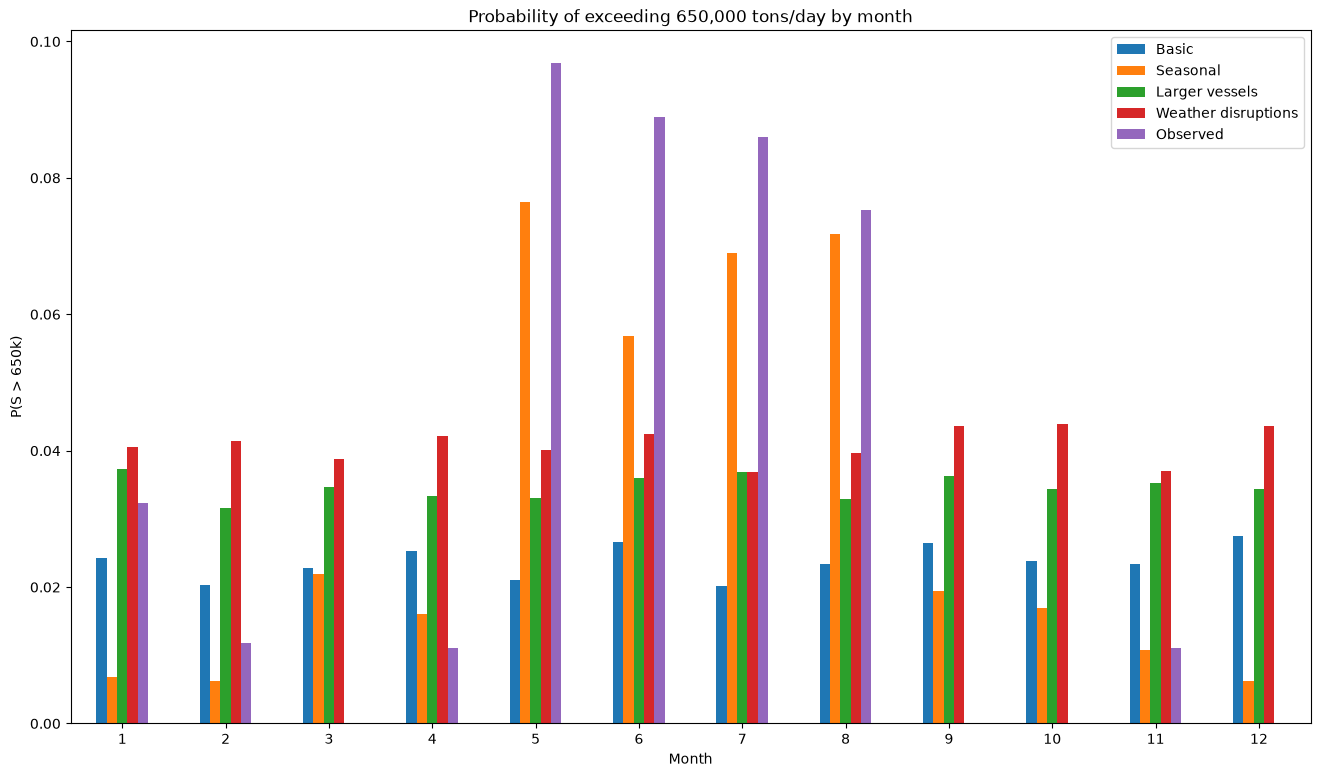

In [23]:
calendar_months = pd.date_range("2025-01-01", periods=365).month

congestion_by_month = pd.DataFrame({
    'Basic': (S_basic > threshold).mean(axis=0),
    'Seasonal': (S_seasonal > threshold).mean(axis=0),
    'Larger vessels': (S_large > threshold).mean(axis=0),
    'Weather disruptions': (S_weather > threshold).mean(axis=0),
}, index=calendar_months).groupby(level=0).mean()
congestion_by_month['Observed'] = (observed_daily > threshold).groupby(observed_daily.index.month).mean()

fig, ax = plt.subplots(figsize = (16, 9))
congestion_by_month.plot(kind='bar', ax=ax)
ax.set_title("Probability of exceeding 650,000 tons/day by month")
ax.set_xlabel("Month")
ax.set_ylabel("P(S > 650k)")
ax.tick_params(axis='x', rotation=0)

fig.savefig("figures/congestion_by_month_scenarios.png", bbox_inches='tight', dpi=300)
congestion_by_month.round(4)

,Basic,Seasonal,Larger vessels,Weather disruptions,Observed
Winter,0.0241,0.0064,0.0345,0.0418,0.0148
Spring,0.0230,0.0384,0.0337,0.0403,0.0362
Summer,0.0234,0.0660,0.0353,0.0397,0.0833
Autumn,0.0246,0.0158,0.0353,0.0415,0.0037


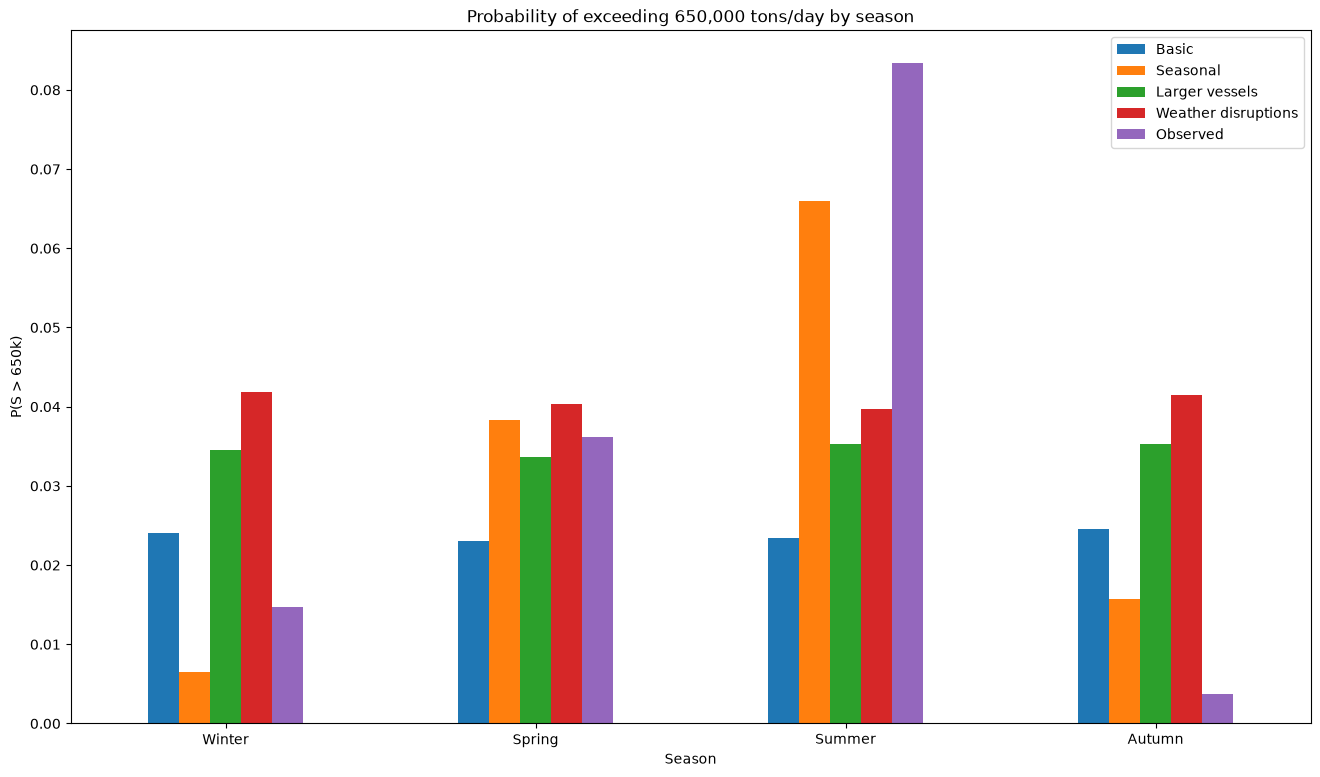

In [19]:
seasons = {12: 'Winter', 1: 'Winter', 2: 'Winter',
           3: 'Spring', 4: 'Spring', 5: 'Spring',
           6: 'Summer', 7: 'Summer', 8: 'Summer',
           9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']

congestion_by_season = pd.DataFrame({
    'Basic': (S_basic > threshold).mean(axis=0),
    'Seasonal': (S_seasonal > threshold).mean(axis=0),
    'Larger vessels': (S_large > threshold).mean(axis=0),
    'Weather disruptions': (S_weather > threshold).mean(axis=0),
}, index=calendar_months.map(seasons)).groupby(level=0).mean().loc[season_order]
congestion_by_season['Observed'] = (observed_daily > threshold).groupby(observed_daily.index.month.map(seasons)).mean()

fig, ax = plt.subplots(figsize = (16, 9))
congestion_by_season.plot(kind='bar', ax=ax)
ax.set_title("Probability of exceeding 650,000 tons/day by season")
ax.set_xlabel("Season")
ax.set_ylabel("P(S > 650k)")
ax.tick_params(axis='x', rotation=0)

congestion_by_season.round(4)